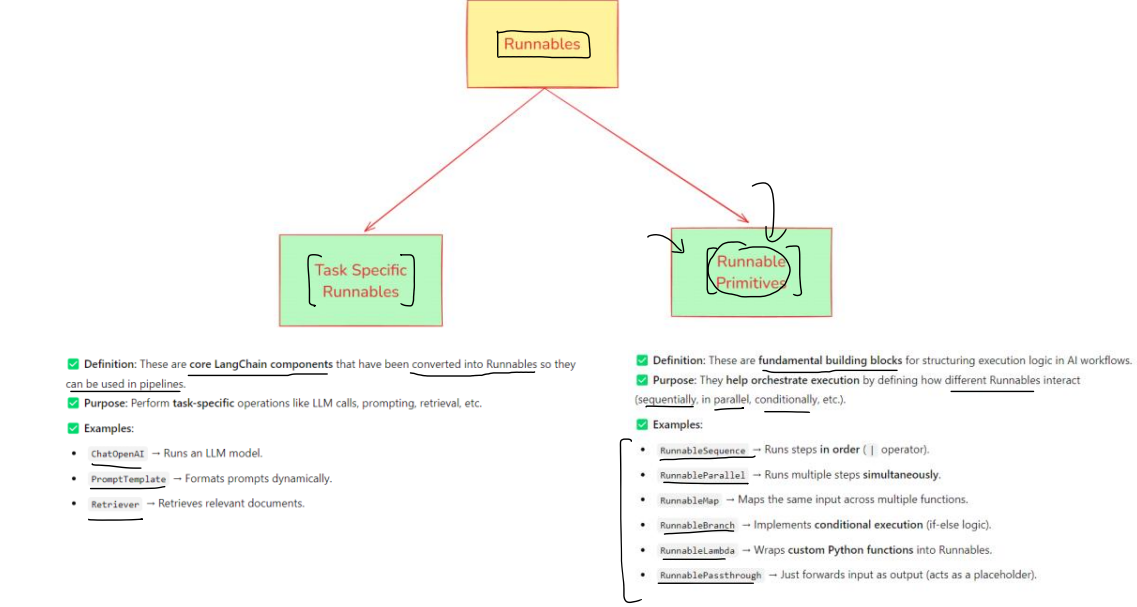

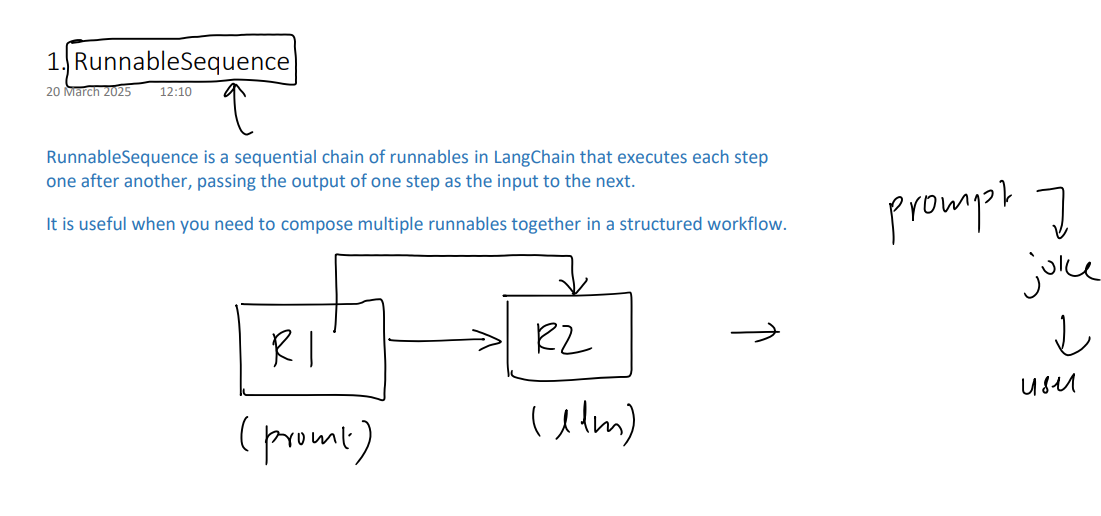

In [3]:
from langchain_groq import ChatGroq
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser
from dotenv import load_dotenv
from langchain_core.runnables import RunnableSequence

load_dotenv()

prompt1 = PromptTemplate(
    template="write 1 short argument about {topic}",
    input_variables=['topic']
)
model = ChatGroq(model ="openai/gpt-oss-120b")

parser = StrOutputParser()

prompt2 = PromptTemplate(
    template="write short pros and cons of argument {text}",
    input_variables=['text']
)
chain = RunnableSequence(prompt1,model,parser,prompt2)

print(chain.invoke({'topic' : 'india'}))

text='write short pros and cons of argument India’s rapid economic growth, combined with its vast demographic dividend, makes it a pivotal player in shaping the future of the global economy. With a young, increasingly skilled workforce and a burgeoning middle class, the country is not only expanding its domestic market but also attracting foreign investment and driving innovation in sectors such as technology, renewable energy, and pharmaceuticals. Moreover, India’s strategic location and strong democratic institutions provide a stable platform for international partnerships. Consequently, overlooking India’s rising influence would be a missed opportunity for any nation or corporation seeking sustainable, long‑term growth in the 21st‑century marketplace.'


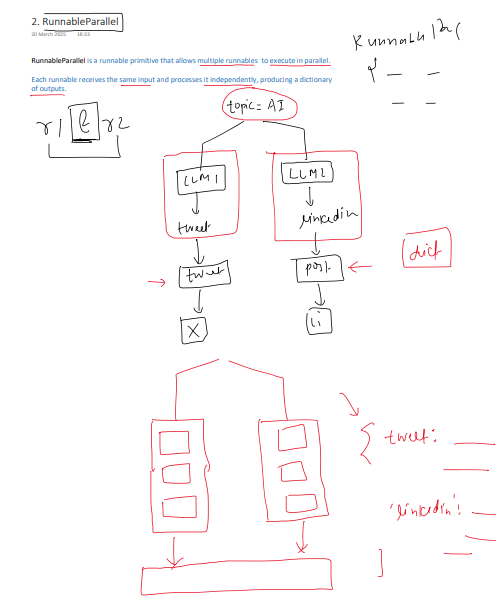

In [5]:
from langchain_groq import ChatGroq
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser
from dotenv import load_dotenv
from langchain_core.runnables import RunnableSequence, RunnableParallel

load_dotenv()

prompt1 = PromptTemplate(
    template='Generate a tweet about {topic}',
    input_variables=['topic']
)

prompt2 = PromptTemplate(
    template='Generate a Linkedin post about {topic}',
    input_variables=['topic']
)

model = ChatGroq(model ="openai/gpt-oss-120b")

parser = StrOutputParser()

parallel_chain = RunnableParallel({
    'tweet': RunnableSequence(prompt1, model, parser),
    'linkedin': RunnableSequence(prompt2, model, parser)
})

result = parallel_chain.invoke({'topic':'Indian Politics'})

print(result['tweet'])
print(result['linkedin'])

India’s political scene keeps evolving—new alliances, vibrant debates, and a citizenry more engaged than ever. 🌏🗳️ #IndianPolitics #DemocracyInAction
🗳️ **Reflections on the Evolving Landscape of Indian Politics** 🗳️  

India’s democratic journey continues to be a compelling case study for leaders, policymakers, and citizens worldwide. Over the past few years, several key trends have emerged that are reshaping the political and socio‑economic fabric of the nation:

| 🔹 **Policy Focus** | 📈 **Economic Reforms** | 🌐 **Global Engagement** |
|---------------------|------------------------|--------------------------|
| • Strengthening social welfare schemes (e.g., health, education) | • Push for manufacturing under *Make in India* and digital infrastructure expansion | • Deepening strategic partnerships across Asia, Europe, and the Americas |
| • Emphasis on climate‑resilient development and renewable energy targets | • Reforms in GST, labor laws, and ease of doing business | • Active parti

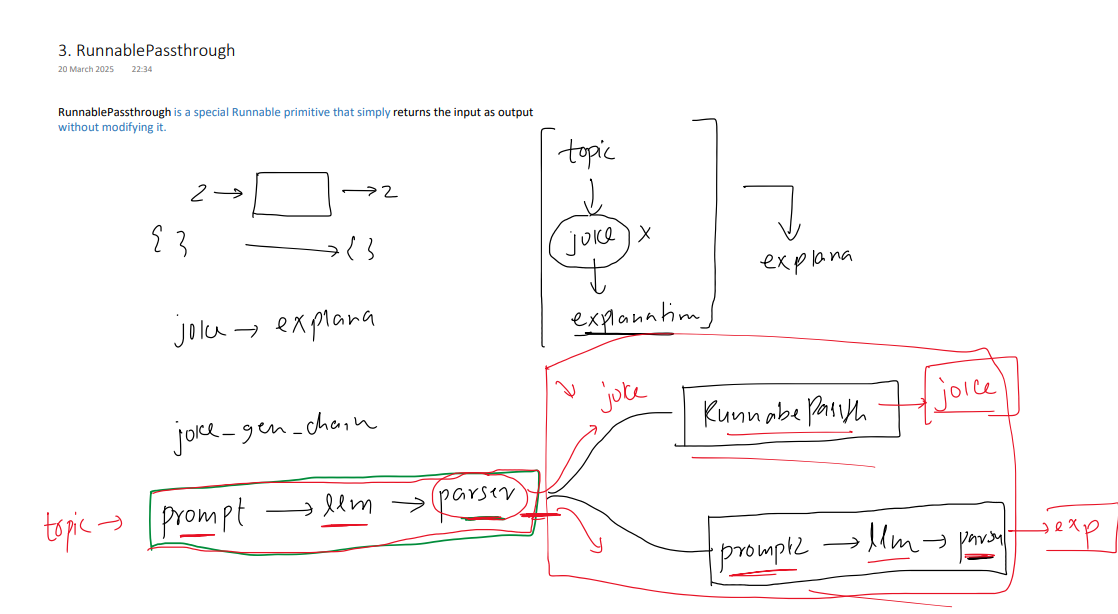

##### ye wha use hote h jha hume input and output same rkhna h example : sequential wale me pehle prompt ka jo output tha vo print nhi ho rha tha last me bss pros and cons ho rhe the to hum passthrough use kr skte h usko print krne ke liye

In [ ]:
from langchain_groq import ChatGroq
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser
from dotenv import load_dotenv
from langchain_core.runnables import RunnableSequence, RunnableParallel,RunnablePassthrough

load_dotenv()

prompt1 = PromptTemplate(
    template='Write a joke about {topic}',
    input_variables=['topic']
)

model = ChatGroq(model ="openai/gpt-oss-120b")

parser = StrOutputParser()

prompt2 = PromptTemplate(
    template='Explain the following joke - {text}',
    input_variables=['text']
)

joke_gen_chain = RunnableSequence(prompt1, model, parser)

parallel_chain = RunnableParallel({
    'joke': RunnablePassthrough(),
    'explanation': RunnableSequence(prompt2, model, parser)
})

final_chain = RunnableSequence(joke_gen_chain, parallel_chain)

print(final_chain.invoke({'topic':'cricket'}))





{'joke': 'Why did the cricket team bring a ladder to the match?\n\nBecause they heard the batsmen were really good at “going up” the scoreboard! 🪜🏏', 'explanation': '**What the joke is doing**\n\nThe humor comes from a classic word‑play technique called a *pun*: the same phrase (“going up”) is understood in two very different ways, and the joke forces the literal meaning onto a figurative expression.\n\n---\n\n### 1. The cricket side of the phrase  \n\n- **Batsmen** – the players who face the bowler and try to score runs.  \n- **Scoreboard** – the board that shows how many runs each side has.  \n- **“Going up the scoreboard”** – a common sports idiom meaning “scoring more runs, increasing the total.” When a batsman hits a good shot or strings together many runs, the numbers on the scoreboard *rise*.\n\nSo, in ordinary cricket talk, saying “the batsmen are really good at going up the scoreboard” simply means they are scoring a lot.\n\n---\n\n### 2. The literal side of the phrase  \n\n- 

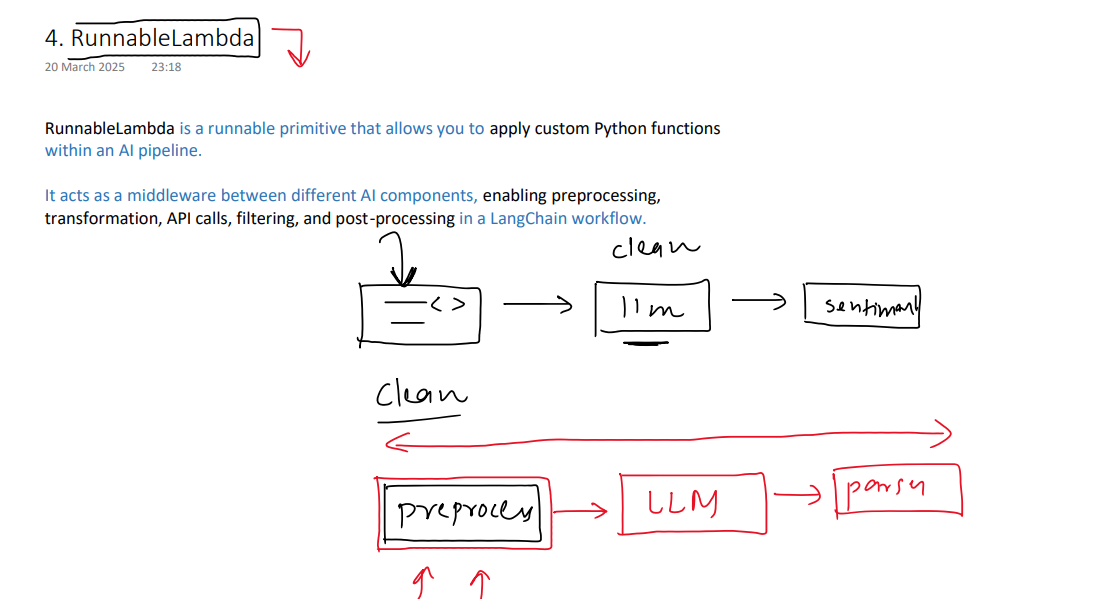

##### kisi py function ko runnable me convert krna, example : a function(runnable) which cleans the data before giving to llm 



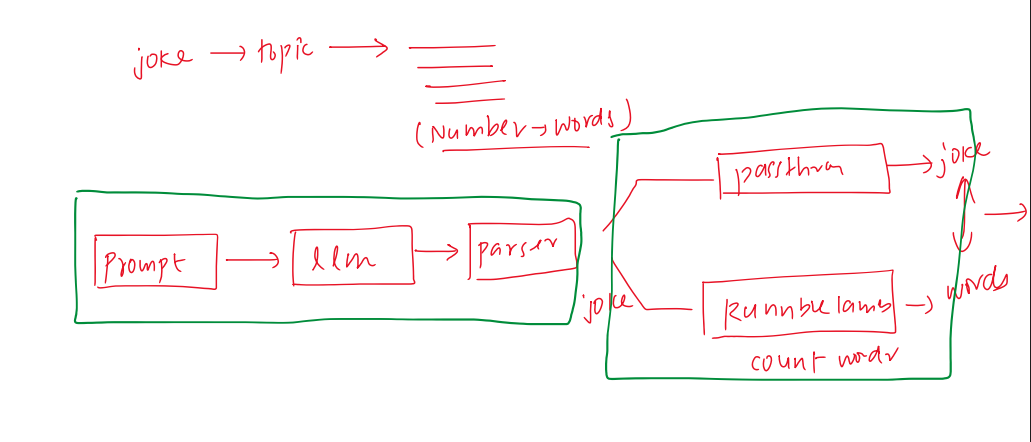

##### joke ke words count krne wala runnable function 

In [7]:
from langchain_groq import ChatGroq
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser
from dotenv import load_dotenv
from langchain_core.runnables import RunnableSequence, RunnableParallel,RunnablePassthrough, RunnableLambda

load_dotenv()

def word_count(text):
    return len(text.split())

prompt = PromptTemplate(
    template='Write a joke about {topic}',
    input_variables=['topic']
)

model = ChatGroq(model ="openai/gpt-oss-120b")

parser = StrOutputParser()

joke_gen_chain = RunnableSequence(prompt, model, parser)

parallel_chain = RunnableParallel({
    'joke': RunnablePassthrough(),
    'word_count': RunnableLambda(word_count)
})

final_chain = RunnableSequence(joke_gen_chain, parallel_chain)

result = final_chain.invoke({'topic':'AI'})

final_result = """{} \n word count - {}""".format(result['joke'], result['word_count'])

print(final_result)

Why did the AI go to therapy?

Because it kept over‑thinking its *neural* network and couldn't stop **deep**‑learning about its feelings! 🤖💭 
 word count - 22


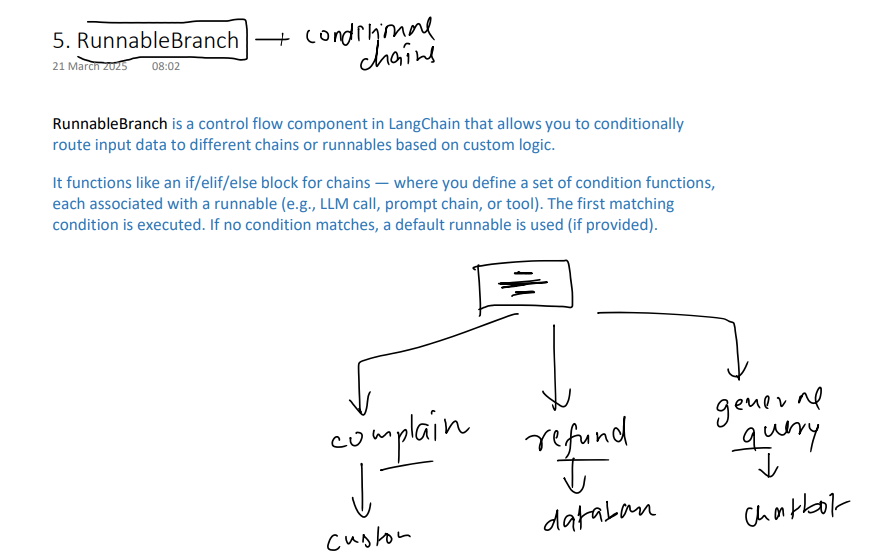

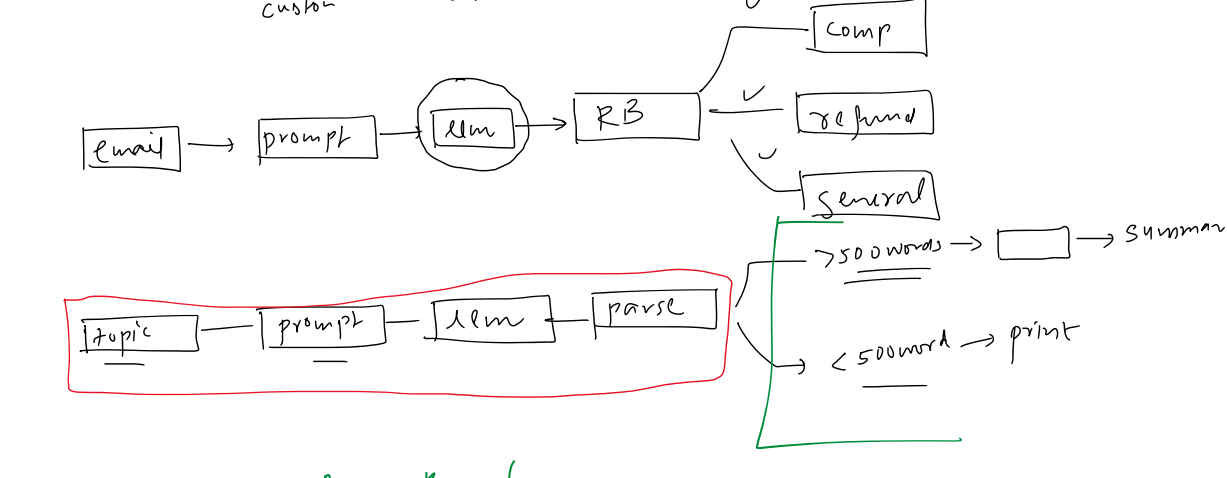

In [11]:
from langchain_groq import ChatGroq
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser
from dotenv import load_dotenv
from langchain_core.runnables import RunnableSequence, RunnableParallel,RunnablePassthrough, RunnableLambda, RunnableBranch

load_dotenv()

prompt1 = PromptTemplate(
    template='Write a detailed report on {topic}',
    input_variables=['topic']
)

prompt2 = PromptTemplate(
    template='Summarize the following text \n {text}',
    input_variables=['text']
) 

model = ChatGroq(model ="openai/gpt-oss-120b")

parser = StrOutputParser()

report_gen_chain = prompt1 | model | parser

branch_chain = RunnableBranch(
    (lambda x: len(x.split())>300, prompt2 | model | parser),
    RunnablePassthrough()
)

final_chain = RunnableSequence(report_gen_chain, branch_chain)

print(final_chain.invoke({'topic':'wars list ind v pak'}))

**Summary – Wars and Major Armed Conflicts Between India and Pakistan (1947‑2024)**  

---

### 1. Overall Picture
- Since partition in 1947, India and Pakistan have fought **four full‑scale wars** and a series of **limited‑scale conflicts and high‑intensity standoffs**.  
- The core dispute is the **status of Jammu & Kashmir**, but the rivalry also involves territorial claims, water resources, ideological competition, and, since 1998, **nuclear deterrence**.  
- Every major clash has ended with a **status‑quo restoration** (cease‑fire lines, diplomatic agreements) rather than a decisive territorial settlement.

---

### 2. Historical Milestones
| Year | Event | Why It Matters |
|------|-------|----------------|
| **1947** | Partition & creation of India & Pakistan | Triggers massive migration and leaves princely states (especially Kashmir) undecided. |
| **Oct 1947** | Maharaja of Kashmir accedes to India after tribal invasion | Sparks the first Indo‑Pak war. |
| **1972** | Simla Agre

LangChain Expression Language (LCEL) is a declarative syntax and unified interface used to chain together AI components like prompts, models, output parsers, and retrievers

example usuage of pipe operator(|) instead pf runnableseq syntax